# California House Price Prediction

## 1. Importing Required Libraries

In [19]:
# Importing Libraries for Data Manipulation
import pandas as pd
import numpy as np

# Importing Libraries for Plotting Graphs
import matplotlib.pyplot as plt
import seaborn as sns

# Importing Libraries for ML work
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Loading the Dataset

In [20]:
# Storing the dataset
housing = fetch_california_housing()

In [21]:
# Printing the dataset description
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [22]:
# Printing the raw data
print(housing.data)

[[   8.3252       41.            6.98412698 ...    2.55555556
    37.88       -122.23      ]
 [   8.3014       21.            6.23813708 ...    2.10984183
    37.86       -122.22      ]
 [   7.2574       52.            8.28813559 ...    2.80225989
    37.85       -122.24      ]
 ...
 [   1.7          17.            5.20554273 ...    2.3256351
    39.43       -121.22      ]
 [   1.8672       18.            5.32951289 ...    2.12320917
    39.43       -121.32      ]
 [   2.3886       16.            5.25471698 ...    2.61698113
    39.37       -121.24      ]]


In [23]:
# Printing the features of the dataset
print(housing.feature_names)

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [24]:
# Printing the target values and name of the target of the dataset
print(housing.target_names)
print(45*"-")
print(housing.target)

['MedHouseVal']
---------------------------------------------
[4.526 3.585 3.521 ... 0.923 0.847 0.894]


## 3. Data Preparation

In [25]:
# Converting the dataset into pandas DataFrame
df = pd.DataFrame(housing.data, columns=housing.feature_names)

In [26]:
# Adding the target column to the dataframe
df["Price"] = housing.target

In [27]:
# Preview of first 5 rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [28]:
# Getting basic information about the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [29]:
# Checking for null values
df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64

In [30]:
# Checking for duplicate values
df.duplicated().sum()

np.int64(0)

In [31]:
# Statistical description about the data
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## 4. Exploratory Data Analysis (EDA)

In [32]:
# Checking the correlation between features
df.corr()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
Price,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


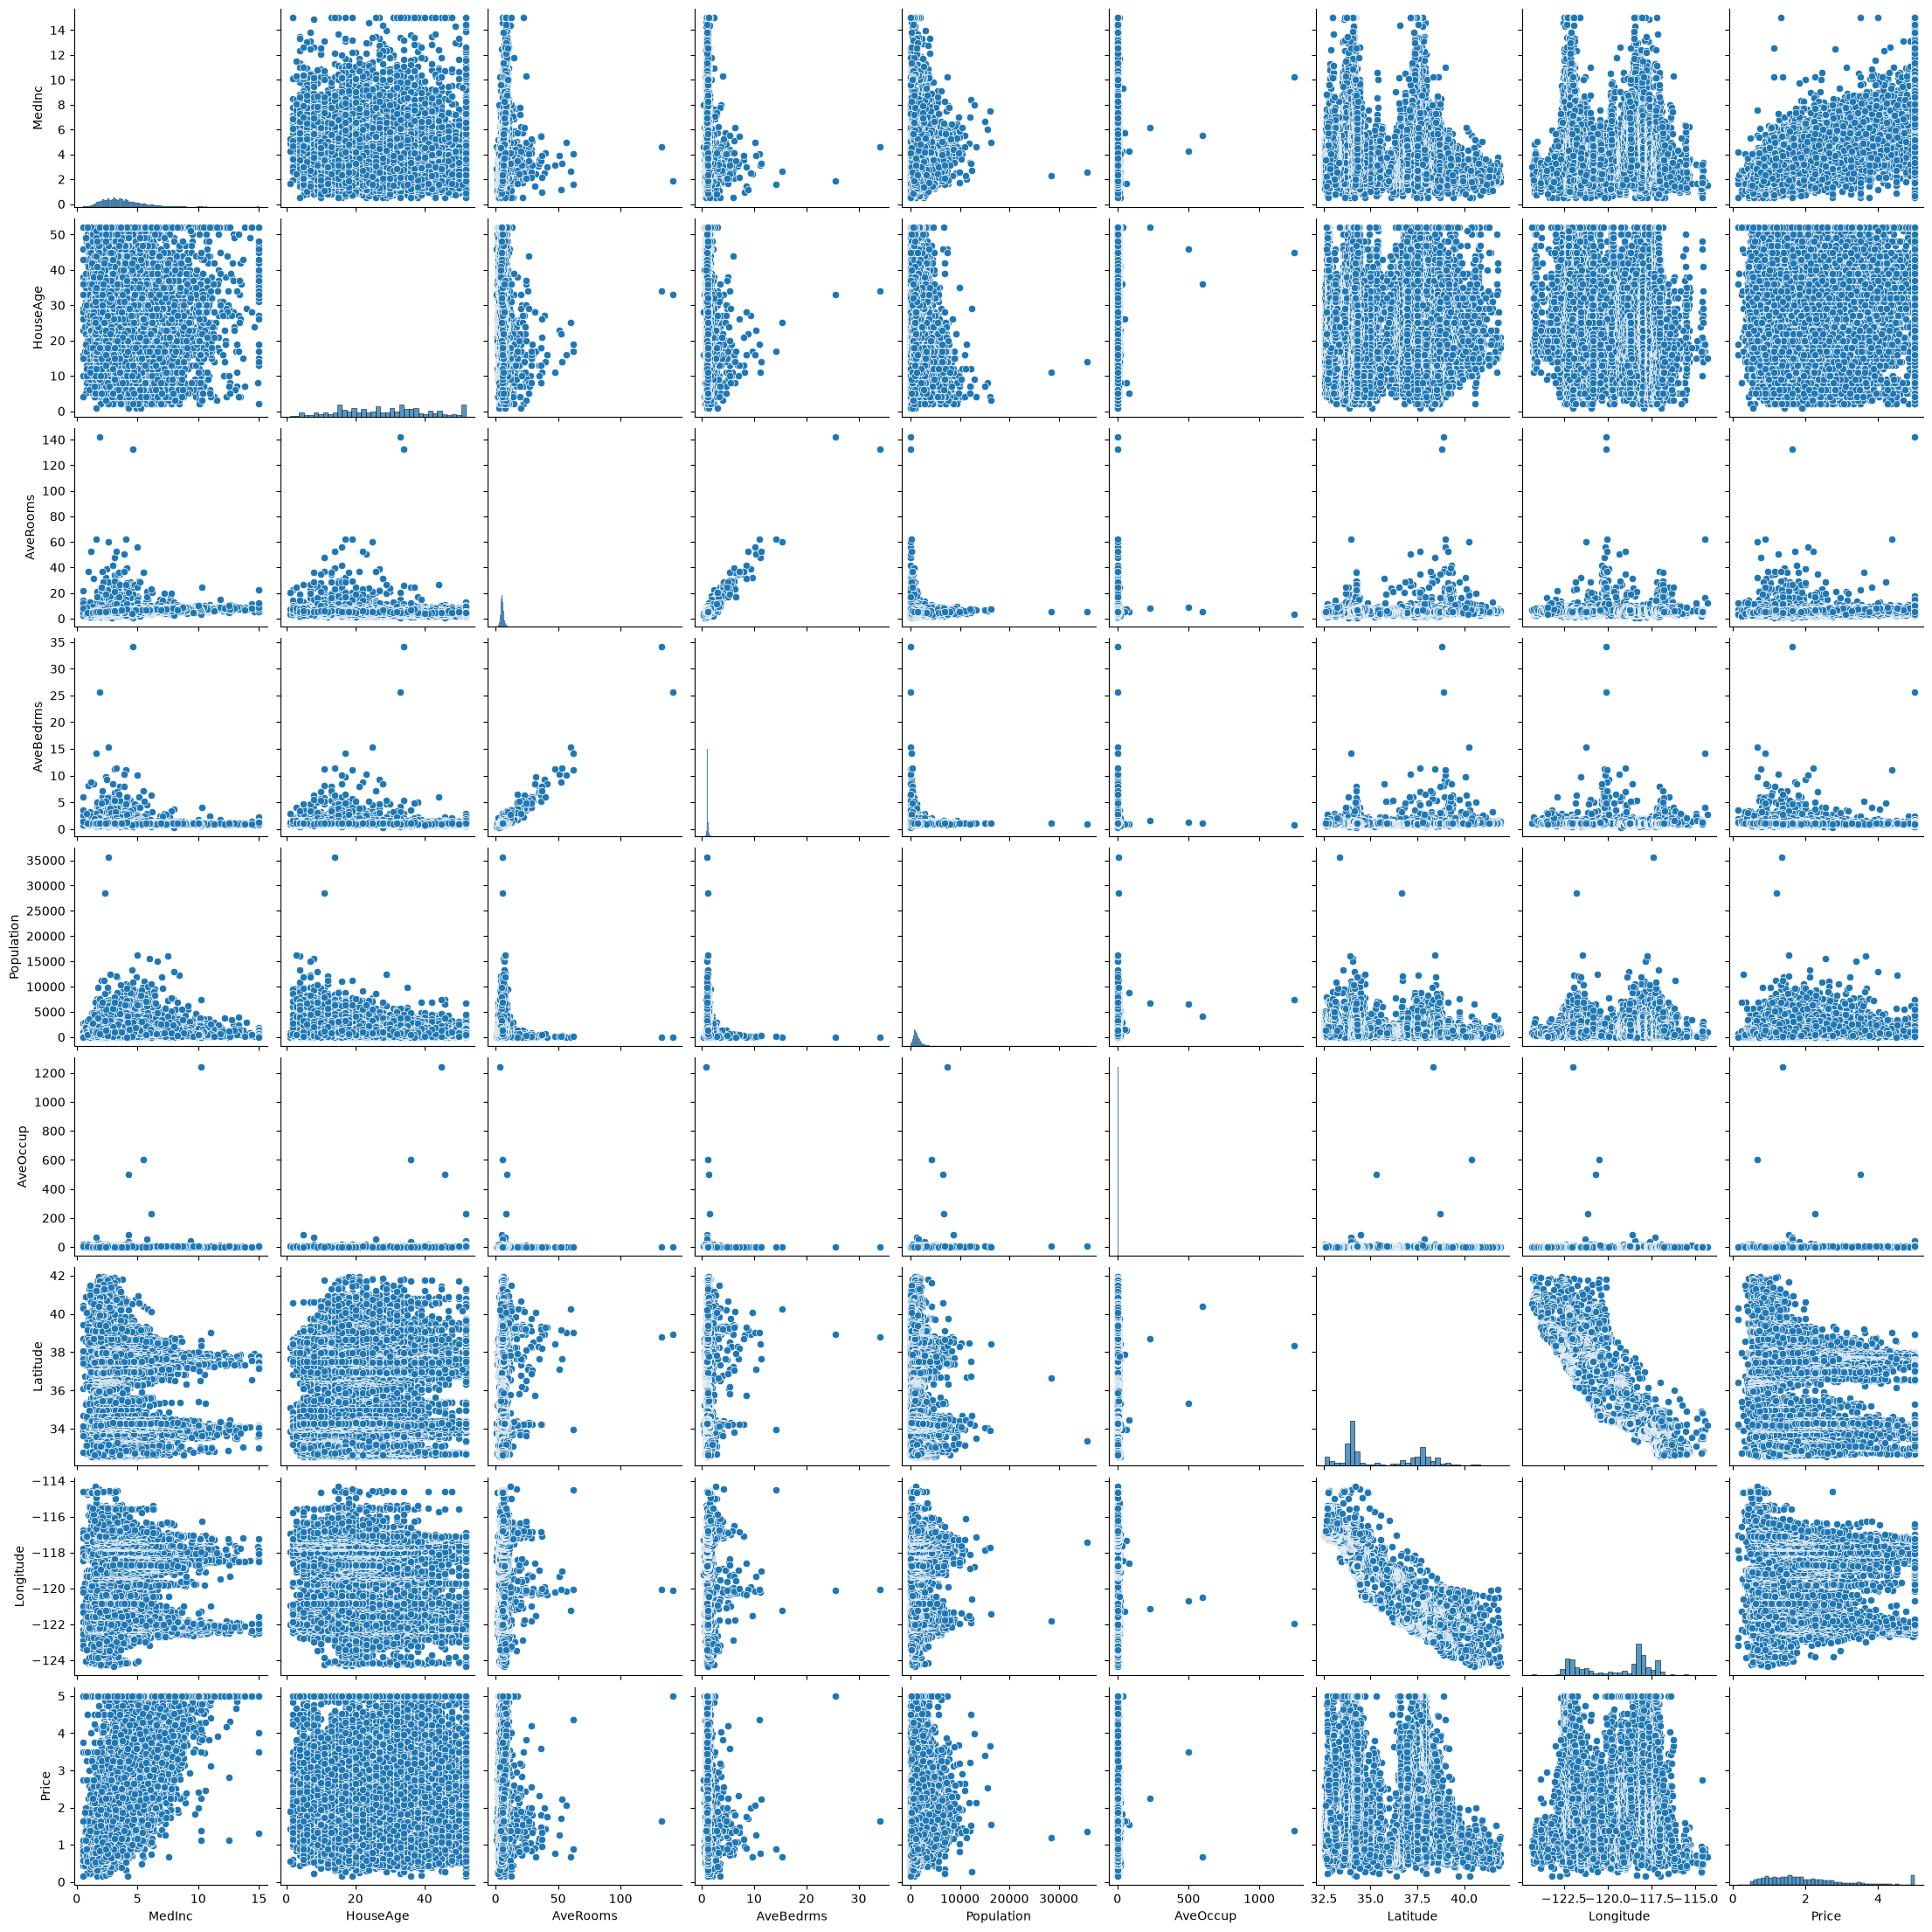

In [33]:
# Visualizing the distributions of features 
sns.pairplot(df)

### Key Findings from Correlation Analysis

- **AveBedrms** and **AveRooms** are highly correlated: **0.847621**
- **Latitude** and **Longitude** are highly correlated: **-0.924664**

Since these pairs are providing duplicate information, we'll drop one feature from each pair to avoid multicollinearity.

### Feature Engineering Strategy

To improve model performance, we'll create new features:
1. **Interaction features**: Capture relationships between variables (e.g., Income × Age)
2. **Polynomial features**: Capture non-linear patterns (e.g., Income²)
3. **Ratio features**: Create meaningful ratios (e.g., Rooms per person)
4. **Log transformations**: Handle skewed distributions

In [34]:
# Dropping highly correlated features
df = df.drop(columns=["AveBedrms", "Longitude"])

# Creating new engineered features
# 1. Rooms per person (housing quality indicator)
df['RoomsPerPerson'] = df['AveRooms'] / df['AveOccup']

# 2. Bedroom ratio (proportion of bedrooms - but we dropped AveBedrms, so skip this)

# 3. Population density indicator
df['PopulationDensity'] = df['Population'] / df['AveOccup']

# 4. Income-Age interaction (wealth accumulation over time)
df['IncomeAge'] = df['MedInc'] * df['HouseAge']

# 5. Location-Income interaction (wealthy areas)
df['IncomeLatitude'] = df['MedInc'] * df['Latitude']

# 6. Polynomial features for MedInc (most important feature)
df['MedInc_squared'] = df['MedInc'] ** 2
df['MedInc_cubed'] = df['MedInc'] ** 3

# 7. Log transformation for skewed features
df['Log_Population'] = np.log1p(df['Population'])
df['Log_AveOccup'] = np.log1p(df['AveOccup'])

df.head()

,MedInc,HouseAge,AveRooms,Population,AveOccup,Latitude,Price,RoomsPerPerson,PopulationDensity,IncomeAge,IncomeLatitude,MedInc_squared,MedInc_cubed,Log_Population,Log_AveOccup
0,8.3252,41.0,6.984127,322.0,2.555556,37.88,4.526,2.732919,126.0,341.3332,315.358576,69.308955,577.010912,5.777652,1.268511
1,8.3014,21.0,6.238137,2401.0,2.109842,37.86,3.585,2.956685,1138.0,174.3294,314.291004,68.913242,572.076387,7.784057,1.134572
2,7.2574,52.0,8.288136,496.0,2.802260,37.85,3.521,2.957661,177.0,377.3848,274.692590,52.669855,382.246204,6.208590,1.335596
3,5.6431,52.0,5.817352,558.0,2.547945,37.85,3.413,2.283154,219.0,293.4412,213.591335,31.844578,179.702136,6.326149,1.266369
4,3.8462,52.0,6.281853,565.0,2.181467,37.85,3.422,2.879646,259.0,200.0024,145.578670,14.793254,56.897815,6.338594,1.157342


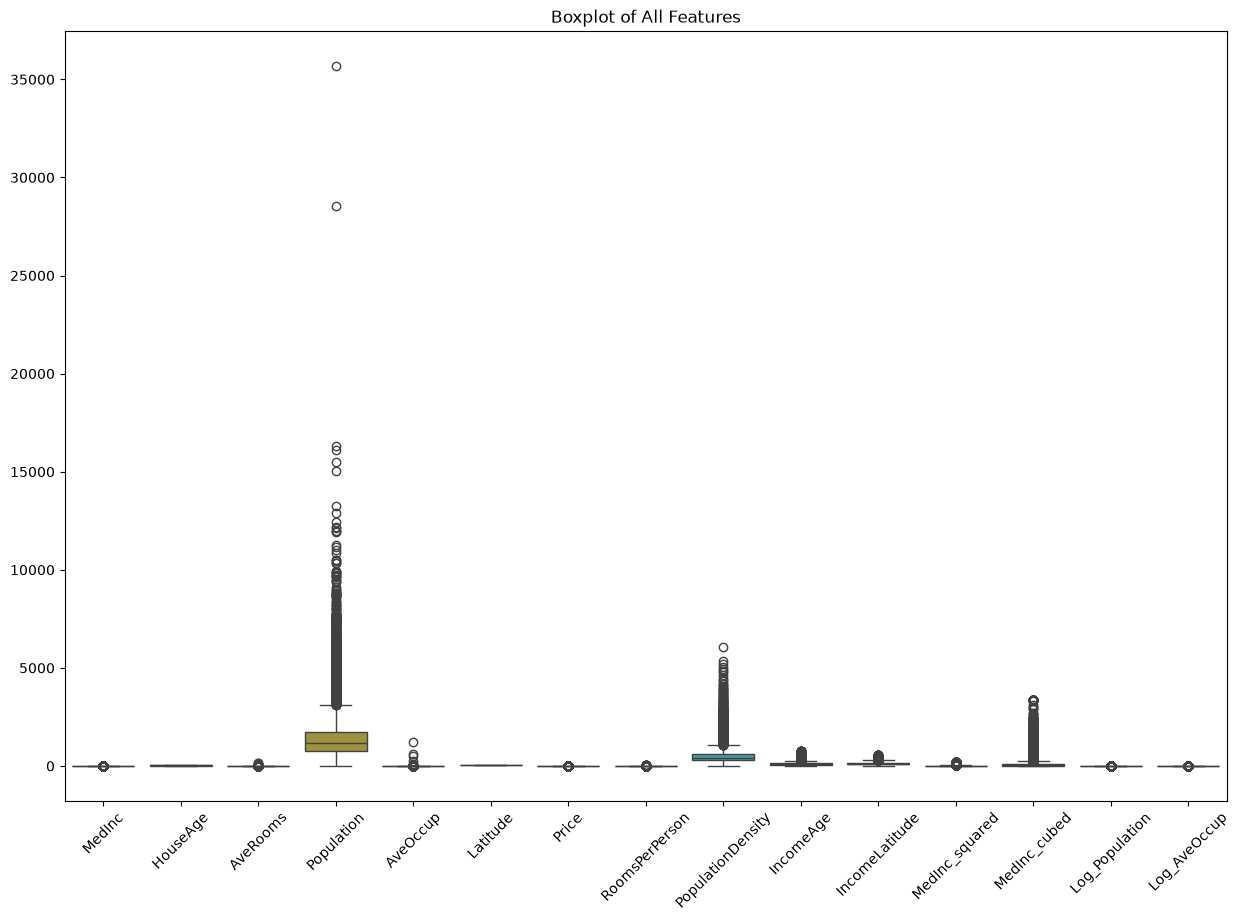

In [35]:
# Checking for outliers using boxplot
fig, ax = plt.subplots(figsize=(15, 10))
sns.boxplot(data=df)
plt.title("Boxplot of All Features")
plt.xticks(rotation=45)
plt.show()

### Observation

From the boxplot, we can see that features like **Population** and **AveOccup** have very large ranges that could overpower other important features. We need to normalize/standardize all features to bring them to the same scale before training the model.

In [36]:
## 5. Feature Engineering

# Splitting the data into independent (X) and dependent (y) features
X = df.drop(columns=["Price"])
y = df["Price"]

In [37]:
# Preview of features
X.head()

,MedInc,HouseAge,AveRooms,Population,AveOccup,Latitude,RoomsPerPerson,PopulationDensity,IncomeAge,IncomeLatitude,MedInc_squared,MedInc_cubed,Log_Population,Log_AveOccup
0,8.3252,41.0,6.984127,322.0,2.555556,37.88,2.732919,126.0,341.3332,315.358576,69.308955,577.010912,5.777652,1.268511
1,8.3014,21.0,6.238137,2401.0,2.109842,37.86,2.956685,1138.0,174.3294,314.291004,68.913242,572.076387,7.784057,1.134572
2,7.2574,52.0,8.288136,496.0,2.802260,37.85,2.957661,177.0,377.3848,274.692590,52.669855,382.246204,6.208590,1.335596
3,5.6431,52.0,5.817352,558.0,2.547945,37.85,2.283154,219.0,293.4412,213.591335,31.844578,179.702136,6.326149,1.266369
4,3.8462,52.0,6.281853,565.0,2.181467,37.85,2.879646,259.0,200.0024,145.578670,14.793254,56.897815,6.338594,1.157342


In [38]:
# Preview of target variable
y.head()

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: Price, dtype: float64

In [39]:
## 6. Train-Test Split

# Splitting the data into training (70%) and testing (30%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [40]:
print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")

Training set size: (14448, 14)
Test set size: (6192, 14)


In [41]:
## 7. Feature Scaling

# Normalizing the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

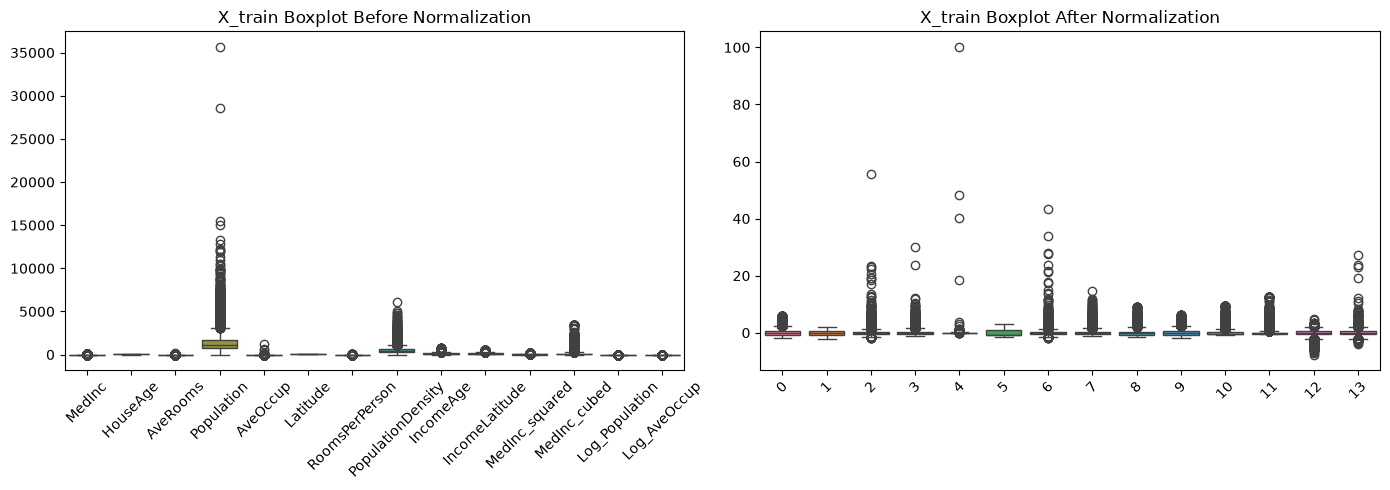

In [42]:
# Visualizing the effect of normalization on training data
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.boxplot(data=X_train, ax=axes[0])
axes[0].set_title("X_train Boxplot Before Normalization")
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=X_train_scaled, ax=axes[1])
axes[1].set_title("X_train Boxplot After Normalization")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [43]:
# Normalizing the test data using the same scaler
X_test_scaled = scaler.transform(X_test)

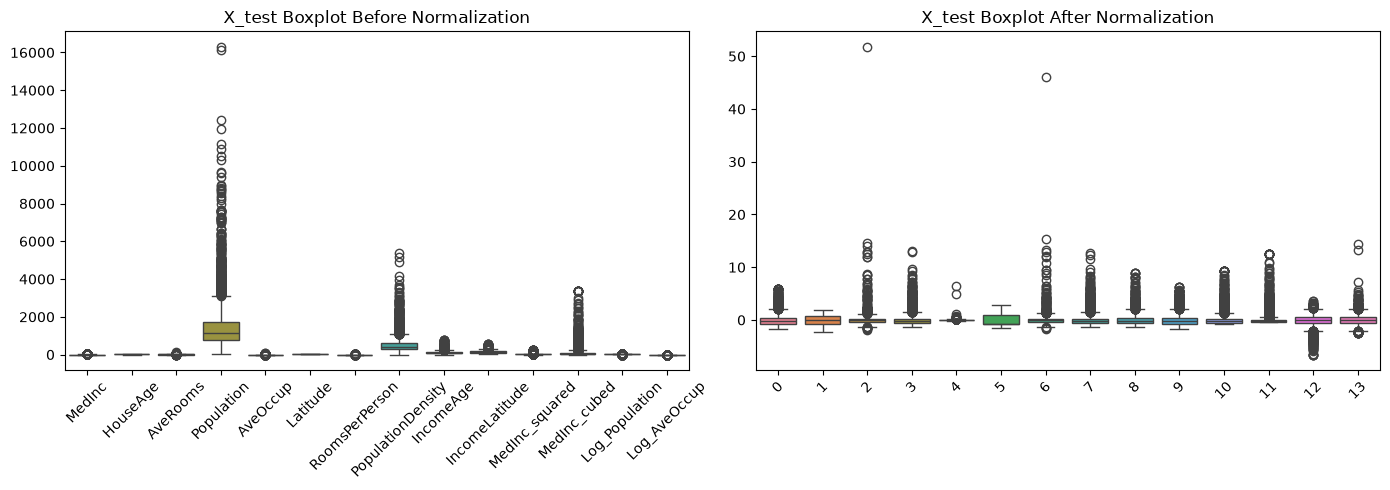

In [44]:
# Visualizing the effect of normalization on test data
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.boxplot(data=X_test, ax=axes[0])
axes[0].set_title("X_test Boxplot Before Normalization")
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=X_test_scaled, ax=axes[1])
axes[1].set_title("X_test Boxplot After Normalization")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 8. Model Training

In [45]:
# Training the Linear Regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [46]:
## 9. Model Prediction

# Making predictions on the test set
y_pred = model.predict(X_test_scaled)

In [47]:
# Preview of predictions
print(f"First 10 predictions: {y_pred[:10]}")
print(f"First 10 actual values: {y_test.values[:10]}")

First 10 predictions: [0.76821826 1.5911371  3.11098274 2.53894166 2.11509307 2.25547912
 2.69123064 1.88586438 2.42877149 4.60906076]
First 10 actual values: [0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]


Feature Importance (sorted by absolute coefficient value):
          Feature  Coefficient  Abs_Coefficient
   MedInc_squared     1.913930         1.913930
     MedInc_cubed    -1.255971         1.255971
           MedInc    -0.896180         0.896180
   IncomeLatitude     0.863589         0.863589
         AveRooms    -0.257105         0.257105
   RoomsPerPerson     0.247933         0.247933
         Latitude    -0.224565         0.224565
PopulationDensity     0.186840         0.186840
         HouseAge     0.171755         0.171755
     Log_AveOccup    -0.163746         0.163746
       Population    -0.114843         0.114843
        IncomeAge     0.109326         0.109326
         AveOccup     0.041113         0.041113
   Log_Population     0.019684         0.019684


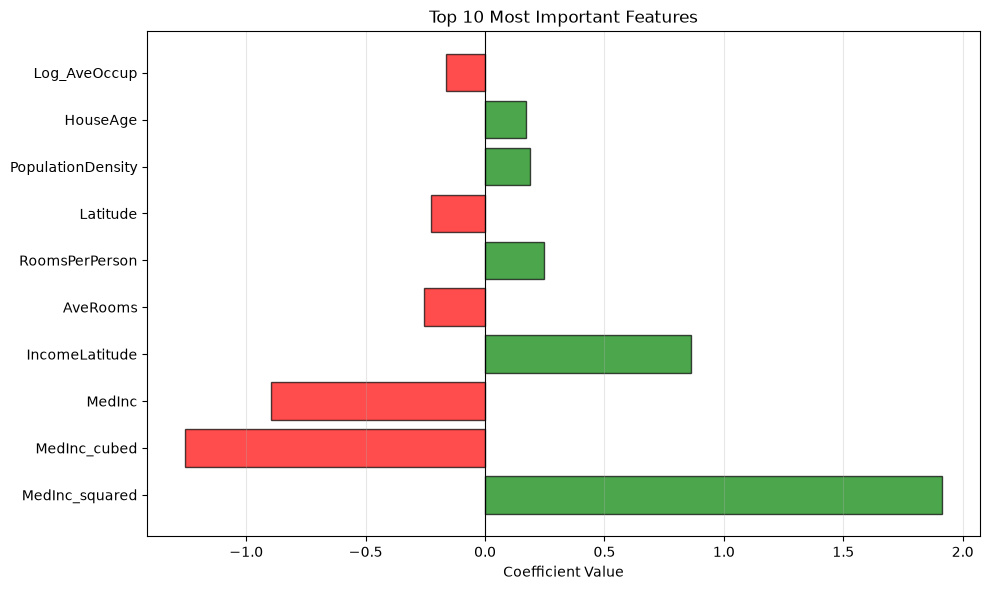


💡 Interpretation:
   • Positive coefficients: Increase in feature → Increase in price
   • Negative coefficients: Increase in feature → Decrease in price
   • Larger absolute value: Stronger impact on predictions


In [48]:
## 10. Feature Importance Analysis

# Displaying model coefficients
feature_names = X.columns
coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model.coef_,
    'Abs_Coefficient': np.abs(model.coef_)
}).sort_values(by='Abs_Coefficient', ascending=False)

print("Feature Importance (sorted by absolute coefficient value):")
print("=" * 60)
print(coefficients.to_string(index=False))
print("=" * 60)

# Visualize top 10 features
plt.figure(figsize=(10, 6))
top_features = coefficients.head(10)
colors = ['green' if x > 0 else 'red' for x in top_features['Coefficient']]
plt.barh(top_features['Feature'], top_features['Coefficient'], color=colors, alpha=0.7, edgecolor='black')
plt.xlabel('Coefficient Value')
plt.title('Top 10 Most Important Features')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("\n💡 Interpretation:")
print("   • Positive coefficients: Increase in feature → Increase in price")
print("   • Negative coefficients: Increase in feature → Decrease in price")
print("   • Larger absolute value: Stronger impact on predictions")

In [49]:
# Model intercept
print(f"Model Intercept: {model.intercept_:.4f}")

Model Intercept: 2.0692


In [50]:
## 11. Model Evaluation

# Calculating evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Calculating adjusted R² score
n = X_test.shape[0]  # Number of samples
k = X_test.shape[1]  # Number of features
adjusted_r2 = 1 - ((1 - r2) * (n - 1)) / (n - k - 1)

# Displaying metrics
print("=" * 50)
print("MODEL PERFORMANCE METRICS")
print("=" * 50)
print(f"Mean Absolute Error (MAE)  : {mae:.4f}")
print(f"Mean Squared Error (MSE)   : {mse:.4f}")
print(f"Root Mean Squared Error    : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")
print(f"Adjusted R² Score          : {adjusted_r2:.4f}")
print(f"Number of Features Used    : {k}")
print("=" * 50)

# Interpreting R² score
if r2 >= 0.70:
    print("\n✓ Excellent model performance!")
elif r2 >= 0.60:
    print("\n✓ Good model performance!")
elif r2 >= 0.50:
    print("\n⚠ Moderate model performance - Feature engineering helped!")
else:
    print("\n⚠ Model needs more improvement")

MODEL PERFORMANCE METRICS
Mean Absolute Error (MAE)  : 0.5265
Mean Squared Error (MSE)   : 0.5094
Root Mean Squared Error    : 0.7137
R² Score                   : 0.6119
Adjusted R² Score          : 0.6111
Number of Features Used    : 14

✓ Good model performance!


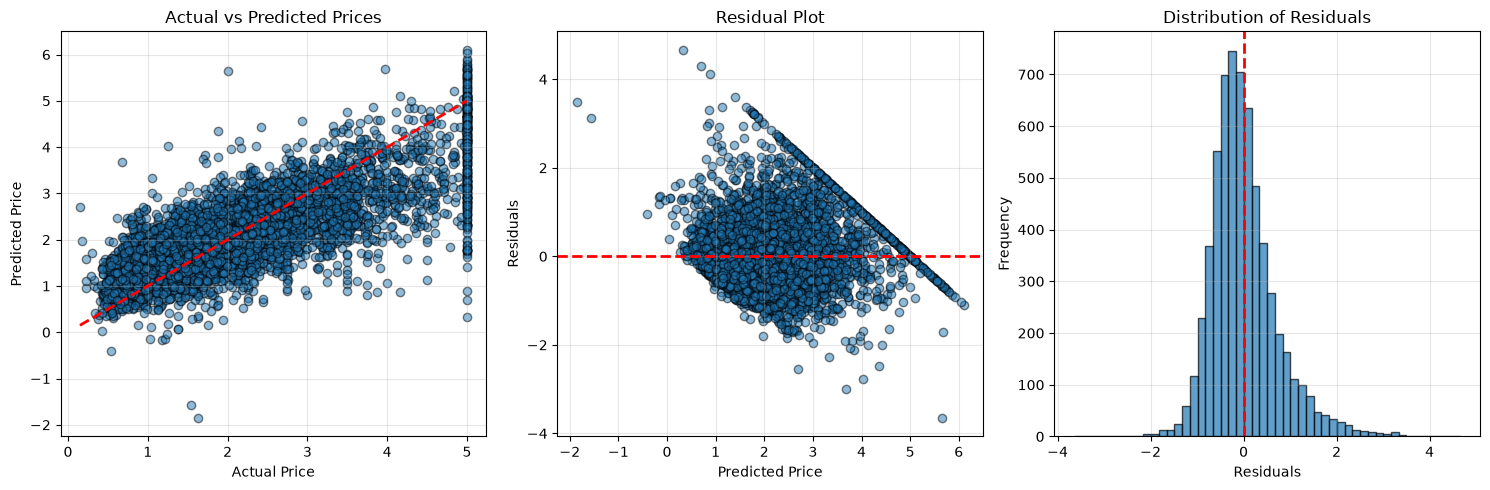


Residual Statistics:
Mean: 0.0042
Std Dev: 0.7137
Min: -3.6534
Max: 4.6674


In [51]:
## 12. Visualization of Results

# Plotting actual vs predicted values
plt.figure(figsize=(15, 5))

# Scatter plot
plt.subplot(1, 3, 1)
plt.scatter(y_test, y_pred, alpha=0.5, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Prices')
plt.grid(True, alpha=0.3)

# Residual plot
plt.subplot(1, 3, 2)
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.5, edgecolors='k')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.grid(True, alpha=0.3)

# Distribution of residuals
plt.subplot(1, 3, 3)
plt.hist(residuals, bins=50, edgecolor='black', alpha=0.7)
plt.axvline(x=0, color='r', linestyle='--', lw=2)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics of residuals
print(f"\nResidual Statistics:")
print(f"Mean: {residuals.mean():.4f}")
print(f"Std Dev: {residuals.std():.4f}")
print(f"Min: {residuals.min():.4f}")
print(f"Max: {residuals.max():.4f}")